***
<h3 align="center">
<strong>DS312: Data Mining and Application</strong>
</h3>

***
<h1 align="center">
Patterns of Recorded Civilian Targeting in Gaza
</h1>

<p style="text-align: center;"><code>Group 7 | Final Project</code><br>
Phase 3: Hypothesis Testing<br>
1st Semester A.Y. 2026-2027 | Instructor: Nicole S. Menorias<br>
<em>Group members: Abdula | Aque | Bautro | Budlong | Mashburn | Orano | Pandi | Prollo</em><br>
Revised: November 16, 2026</p>

---

## 4. Phase 3: Hypothesis Testing

In this part of Phase 3 we test two hypotheses that come from our business questions: **BQ1 (does the focal share change before and after October 7, 2023?)** and **BQ2 (how are focal events spread across event types?)**. We use the cleaned Gaza event master from Phase 2 and the counts and sparse-cell diagnostics that Phase 3 handed off. We keep the earlier conventions: the cut-off is October 7, 2023, a focal event is an ACLED civilian-targeting flag together with the exact label "Civilians (Palestine)" in either actor field, and every share is focal events divided by the political-violence records of the same group and period. Counts are shown next to every rate.

### 4.1 Hypotheses and Test Plan

| Item | Hypothesis A | Hypothesis B |
| :--- | :--- | :--- |
| **Business question** | BQ1 | BQ2 |
| **Question** | Is the focal share of political-violence records different before and after Oct 7, 2023? | Does the focal share of political-violence records differ across recorded event types? |
| **Variables** (unit: one political-violence record) | Period (2 groups) by focal status (focal or not) | Event type (5 groups) by focal status (focal or not) |
| **H0** | The focal share is the same in both periods. | The focal share is the same in every event type. |
| **H1** | The focal share differs between the two periods. | The focal share differs for at least one event type. |
| **Test** | Pearson chi-square test of independence (2 × 2) | Chi-square test of independence with a Monte Carlo p-value (5 × 2) |
| **Why this test** | Both variables are categories, so we compare proportions. The Phase 3 preflight gave a smallest expected count of 183.17, so the ordinary large-sample test is valid. | The Phase 3 preflight gave a smallest expected count of 3.30 and 4 of 10 cells below 5 (the Protests and Riots rows), so the large-sample p-value is not reliable. We simulate the p-value as in Phase 2 and keep all five event types. |
| **Effect size** | Difference in shares, risk ratio, odds ratio and phi, with 95% intervals | Cramér's V and Pearson residuals |
| **Robustness checks** | Fisher exact test and continuity correction; the same comparison inside Explosions/Remote violence and inside Violence against civilians | Protests and Riots pooled so every expected count is at least 5; Violence against civilians compared directly with Explosions/Remote violence |

**Why chi-square tests and not a t-test or a correlation test.** In both questions the outcome is a category (focal or not focal), not a number, so a t-test has nothing to average and a correlation test needs two numeric measures. The weekly numeric measures in Phase 3 (Chart 11, Spearman correlations) answer a different question, week-to-week persistence for the Phase 4 models, and are not tested here.

**Decision rule.** We use alpha = 0.05 for each test. Because we run two primary tests we also report a Bonferroni-adjusted level of 0.025 (0.05 / 2); both conclusions are the same under either level. The robustness checks show how stable each result is. They are not extra hypotheses and we do not use them to claim new findings.

**Interpretation boundaries.**
- We describe **recorded ACLED events** and the project's own focal rule. The rule is a reproducible coding convention, not proof of intent, responsibility or legal classification.
- A zero means zero **recorded** events. It is not evidence that no harm occurred.
- With 22,753 records almost any difference gives a very small p-value, so we read the effect size and its interval first and the p-value second.
- Events are related across time and place, so records are not fully independent and the p-values are probably smaller than an independent sample would give. The tests are exploratory, as in Phase 3, and neither one shows cause.

### 4.2 Setup and Data Loading

We load only the Phase 2 event master and only the six columns the two tests use, so the notebook runs in a few seconds. The weekly tables and the focal-incident file are not needed here. The period label is checked against the event date, and the counts are compared with Phases 2 and 3 because the text below quotes them.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import MonteCarloMethod, binomtest, chi2_contingency, fisher_exact
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9})
plt.rcParams["axes.grid.axis"] = "y"  # horizontal gridlines only; horizontal bars and heatmaps adjust below

SEED = 42              # fixes the Monte Carlo draws, so reruns give identical p-values
ALPHA = 0.05           # significance level for each test
N_RESAMPLES = 99_999   # simulated tables for the Monte Carlo test, the same number as in Phase 2
Z = 1.96               # 95% normal critical value for the effect-size intervals

# Colours reused from Phase 3: focal = dark red, other/non-focal = blue, context = grey
C_FOCAL, C_OTHER, C_GREY = "#8D3B42", "#315A7D", "#9AA5B1"

In [27]:
from pathlib import Path

PROJECT_DIR = Path("/Users/sasha/Documents/dma_group7")

def find_data_dir(filename=None):
    candidate = PROJECT_DIR / "data" / "processed"

    if not candidate.is_dir():
        raise FileNotFoundError(
            f"Processed folder does not exist: {candidate}"
        )

    if filename is not None and not (candidate / filename).is_file():
        raise FileNotFoundError(
            f"File '{filename}' not found inside {candidate}. "
            f"Available files: {[f.name for f in candidate.iterdir()]}"
        )

    return candidate

DATA_DIR = find_data_dir()

print("Reading Phase 2 output from:", DATA_DIR.resolve())

Reading Phase 2 output from: /Users/sasha/Documents/dma_group7/data/processed


In [28]:
print("Files inside processed folder:")

for file in DATA_DIR.iterdir():
    print(file.name)

Files inside processed folder:
.DS_Store
acled_focal_incidents.csv
acled_events_clean.csv
acled_gaza_week.csv
acled_district_week.csv


In [29]:
import pandas as pd

events = pd.read_csv(DATA_DIR / "acled_events_clean.csv")

print("Dataset shape:", events.shape)
print("\nColumn names:")
print(events.columns.tolist())

print("\nFirst 5 rows:")
display(events.head())

Dataset shape: (26664, 43)

Column names:
['event_id_cnty', 'event_date', 'year', 'time_precision', 'disorder_type', 'event_type', 'sub_event_type', 'actor1', 'assoc_actor_1', 'inter1', 'actor2', 'assoc_actor_2', 'inter2', 'interaction', 'civilian_targeting', 'iso', 'region', 'country', 'admin1', 'admin2', 'location', 'latitude', 'longitude', 'geo_precision', 'source', 'source_scale', 'notes', 'fatalities', 'tags', 'timestamp', 'district_missing', 'high_fatalities_review', 'period', 'month_start', 'week_start', 'fatalities_log1p', 'targeting_flagged', 'political_violence', 'focal_event', 'geo_precision_1', 'time_precision_1', 'coastal_location', 'land_spatial_eligible']

First 5 rows:


,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,month_start,week_start,fatalities_log1p,targeting_flagged,political_violence,focal_event,geo_precision_1,time_precision_1,coastal_location,land_spatial_eligible
0,PSE13133,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,True,False
1,PSE13151,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False
2,PSE23994,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False
3,PSE13152,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,True,False
4,PSE24024,2022-01-01,2022,1,Strategic developments,Strategic developments,Other,Military Forces of Israel (2021-2022),NaN,External/Other forces,...,2022-01-01,2022-01-01,0.0,False,False,False,False,True,False,False


In [30]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
CUTOFF = pd.Timestamp("2023-10-07")
EVENT_TYPES = ["Explosions/Remote violence", "Violence against civilians", "Battles", "Protests", "Riots"]

# Political-violence records are the denominator for every focal share (as in Phase 3)
political = master.loc[master.political_violence].copy()
period_from_date = np.where(master.event_date.ge(CUTOFF), AFTER, BEFORE)

# Integrity check: compare what we loaded with the figures documented in Phases 2 and 3.
checks = pd.DataFrame([
    ("Event master rows", 26664, len(master)),
    ("Records whose period label disagrees with the event date", 0, int((master.period != period_from_date).sum())),
    ("Repeated event IDs", 0, int(master.event_id_cnty.duplicated().sum())),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Focal events outside political violence", 0, int((master.focal_event & ~master.political_violence).sum())),
    ("Event types among political-violence records", 5, int(political.event_type.nunique())),
    ("Political-violence records with an unexpected event type", 0, int((~political.event_type.isin(EVENT_TYPES)).sum())),
], columns=["Check", "Expected (Phases 2 and 3)", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected (Phases 2 and 3)"], checks["Observed"])]
display(checks)
print("All checks match Phases 2 and 3." if checks.Match.all() else
      "Some checks differ: review the table above before using the results, because the text below quotes these counts.")

,Check,Expected (Phases 2 and 3),Observed,Match
0,Event master rows,26664,26664,True
1,Records whose period label disagrees with the ...,0,0,True
2,Repeated event IDs,0,0,True
3,"Focal events, all",10714,10714,True
4,Focal events before Oct 7,63,63,True
5,Focal events Oct 7 onward,10651,10651,True
6,Political-violence records before Oct 7,389,389,True
7,Political-violence records Oct 7 onward,22364,22364,True
8,Focal events outside political violence,0,0,True
9,Event types among political-violence records,5,5,True


All checks match Phases 2 and 3.


The helper functions below keep the two tests consistent. `focal_table` builds each contingency table, `preflight` prints the smallest expected count (the check that decides which p-value procedure is valid), `wilson_ci` gives 95% intervals for the charts, and `fmt_p` prints very small p-values readably.

In [31]:
def focal_table(frame, by, order):
    """Focal / not-focal counts for each group in `order`. reindex keeps empty groups, and it reads
    [True, False] as column labels (a [True, False] list passed to .loc would be read as a boolean mask)."""
    tab = pd.crosstab(frame[by], frame.focal_event).reindex(index=order, columns=[True, False], fill_value=0)
    tab.columns = ["Focal", "Not focal"]
    return tab

def expected_counts(table):
    """Expected counts under independence: row total x column total / grand total."""
    t = np.asarray(table, dtype=float)
    return np.outer(t.sum(axis=1), t.sum(axis=0)) / t.sum()

def preflight(label, table):
    """Print the sparse-cell diagnostic that decides which p-value procedure is valid."""
    e = expected_counts(table)
    print(f"{label}: smallest expected count = {e.min():.2f}; cells below 5 = {(e < 5).sum()} of {e.size}")
    return e

def wilson_ci(k, n):
    """95% Wilson interval for a share; it stays inside 0 to 1 and works when k = 0 or k = n."""
    ci = binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="wilson")
    return ci.low, ci.high

def fmt_p(p, monte_carlo=False):
    """Readable p-value. Floating point underflows to 0.0 for very small chi-square p-values, and a
    Monte Carlo p-value cannot go below 1 / (N_RESAMPLES + 1)."""
    if monte_carlo:
        floor = 1 / (N_RESAMPLES + 1)
        return f"p < {floor:.5f}" if np.isclose(p, floor) else f"p = {p:.5f}"
    return "p < 1e-300" if p == 0 else f"p = {p:.2e}"

### 4.3 Hypothesis A: focal share before vs. after October 7, 2023 (BQ1)

**Question.** Is the focal share of political-violence records different before and after October 7, 2023?

**H0:** the focal share is the same in both periods. <br> 
**H1:** it differs. <br>
**Test:** Pearson chi-square test of independence on the 2 × 2 table of period by focal status, without continuity correction because every expected count is large. The periods are 644 and 725 days long, but a share is a ratio inside each period, so period length does not enter the test; it matters only for the per-week rates reported in Phase 3. We also report Fisher's exact test and the continuity-corrected test to show that the p-value does not depend on that choice.

In [32]:
period_table = focal_table(political, "period", [BEFORE, AFTER])
display(period_table.assign(Total=period_table.sum(axis=1),
                            Focal_share=(period_table.Focal / period_table.sum(axis=1)).round(3)))
preflight("A: period x focal", period_table)

tab_A = period_table.to_numpy()
chi2_A, p_A, dof_A, _ = chi2_contingency(tab_A, correction=False)   # Pearson chi-square, no continuity correction
p_A_yates = chi2_contingency(tab_A, correction=True)[1]             # sensitivity: with continuity correction
p_A_fisher = fisher_exact(tab_A)[1]                                 # sensitivity: exact test
n_A = tab_A.sum()
phi_A = np.sqrt(chi2_A / n_A)

# Effect sizes with 95% intervals (normal approximation; the ratios use the log scale)
(f_b, nf_b), (f_a, nf_a) = tab_A
n_b, n_a = f_b + nf_b, f_a + nf_a
share_b, share_a = f_b / n_b, f_a / n_a
diff = share_a - share_b
se_diff = np.sqrt(share_b * (1 - share_b) / n_b + share_a * (1 - share_a) / n_a)
rr = share_a / share_b
se_rr = np.sqrt((1 - share_a) / f_a + (1 - share_b) / f_b)
odds = (f_a * nf_b) / (f_b * nf_a)
se_or = np.sqrt(1 / f_a + 1 / nf_a + 1 / f_b + 1 / nf_b)

print(f"Pearson chi-square({dof_A}) = {chi2_A:,.2f}, {fmt_p(p_A)} (n = {n_A:,}, phi = {phi_A:.3f})")
print(f"Sensitivity: with continuity correction {fmt_p(p_A_yates)}; Fisher exact {fmt_p(p_A_fisher)}")
print(f"Focal share: {share_b:.1%} ({f_b:,} / {n_b:,}) before vs. {share_a:.1%} ({f_a:,} / {n_a:,}) from Oct 7 onward")
print(f"Difference = {diff * 100:+.1f} points (95% CI {(diff - Z * se_diff) * 100:+.1f} to {(diff + Z * se_diff) * 100:+.1f}); "
      f"risk ratio = {rr:.2f} ({rr * np.exp(-Z * se_rr):.2f} to {rr * np.exp(Z * se_rr):.2f}); "
      f"odds ratio = {odds:.2f} ({odds * np.exp(-Z * se_or):.2f} to {odds * np.exp(Z * se_or):.2f})")
decision_A = "Reject H0" if p_A < ALPHA / 2 else "Fail to reject H0"
print(f"Decision: {decision_A} (alpha = {ALPHA}, Bonferroni-adjusted to {ALPHA / 2} for the two primary tests)")

,Focal,Not focal,Total,Focal_share
period,,,,
"Before Oct 7, 2023",63,326,389,0.162
"Oct 7, 2023 onward",10651,11713,22364,0.476


A: period x focal: smallest expected count = 183.17; cells below 5 = 0 of 4
Pearson chi-square(1) = 151.60, p = 7.76e-35 (n = 22,753, phi = 0.082)
Sensitivity: with continuity correction p = 1.46e-34; Fisher exact p = 3.75e-38
Focal share: 16.2% (63 / 389) before vs. 47.6% (10,651 / 22,364) from Oct 7 onward
Difference = +31.4 points (95% CI +27.7 to +35.1); risk ratio = 2.94 (2.34 to 3.69); odds ratio = 4.71 (3.59 to 6.17)
Decision: Reject H0 (alpha = 0.05, Bonferroni-adjusted to 0.025 for the two primary tests)


**Interpretation.** We reject H0 (chi-square(1) = 151.60, p = 7.8e-35; Fisher exact p = 3.8e-38). The focal share is 16.2% (63 of 389 records) before Oct 7, 2023 and 47.6% (10,651 of 22,364) from Oct 7 onward, a rise of 31.4 percentage points (95% CI 27.7 to 35.1). A record from Oct 7 onward is about 2.9 times as likely to be focal (risk ratio 2.94, 95% CI 2.34 to 3.69; odds ratio 4.71, 95% CI 3.59 to 6.17) (BQ1). In plain terms, a gap this large would almost never appear by chance if the focal share were the same in both periods. Phi is only 0.08 because the two groups are very unequal in size (389 vs. 22,364 records, as noted in Phase 3), so the share difference and the odds ratio describe the size of the change better. The earlier share rests on 63 focal events, so its interval is wide (12.9% to 20.2%), and the test cannot separate a real change in events from a change in coding or reporting coverage.

#### 4.3.1 Does the rise hold inside event types? (BQ1, BQ2)

**Question.** The overall rise could come from a change in the event-type mix instead of a change inside event types. In Phase 3 (Chart 7) Explosions/Remote violence grows from 77% to 89% of records, and Battles never contain focal events. We therefore repeat the comparison inside the two event types that contain focal events. This is a robustness check, not a third hypothesis. We use the chi-square test when every expected count is at least 5 and Fisher's exact test otherwise, and groups with fewer than 30 records are marked in the chart.

,Before: focal / records,Before share,After: focal / records,After share,Smallest expected,Test,p-value
Event type,,,,,,,
Explosions/Remote violence,39 / 298,0.131,"9,867 / 19,978",0.494,145.59,Chi-square,p = 1.50e-35
Violence against civilians,24 / 24,1.000,784 / 790,0.992,0.18,Fisher exact,p = 1.00e+00


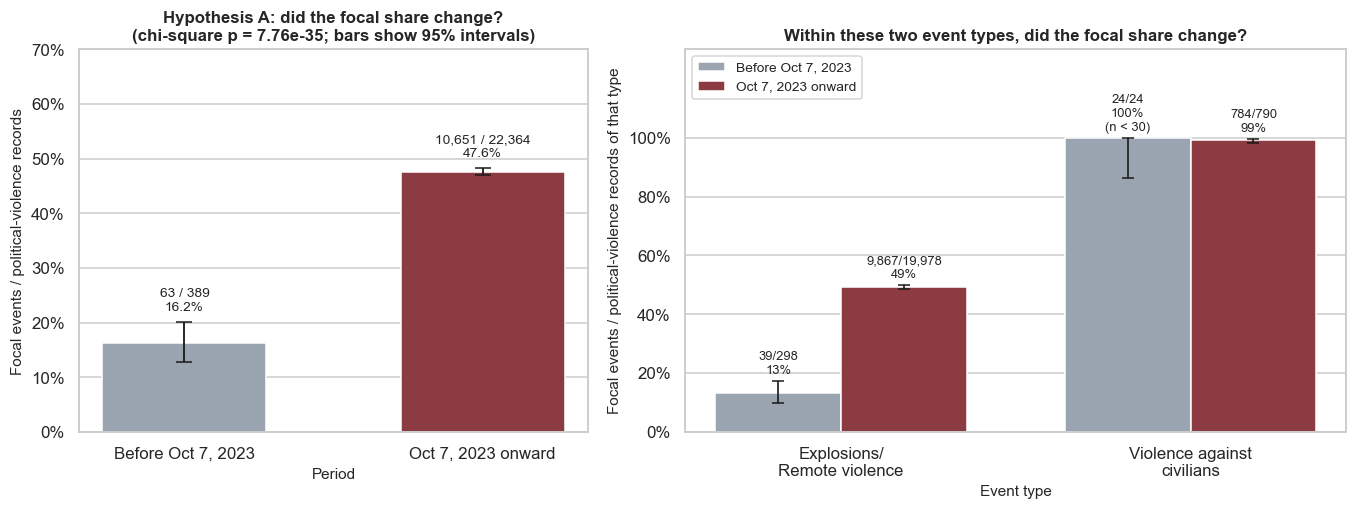

In [33]:
# Within each event type that contains focal events: is the period difference still there?
within_tabs, within_rows = {}, []
for etype in EVENT_TYPES[:2]:
    t = focal_table(political.loc[political.event_type == etype], "period", [BEFORE, AFTER]).to_numpy()
    within_tabs[etype] = t
    e_min = expected_counts(t).min()
    if e_min >= 5:   # the large-sample test is valid only when every expected count is at least 5
        test_name, p_val = "Chi-square", chi2_contingency(t, correction=False)[1]
    else:
        test_name, p_val = "Fisher exact", fisher_exact(t)[1]
    within_rows.append({"Event type": etype,
                        "Before: focal / records": f"{t[0, 0]:,} / {t[0].sum():,}", "Before share": t[0, 0] / t[0].sum(),
                        "After: focal / records": f"{t[1, 0]:,} / {t[1].sum():,}", "After share": t[1, 0] / t[1].sum(),
                        "Smallest expected": e_min, "Test": test_name, "p-value": fmt_p(p_val)})
display(pd.DataFrame(within_rows).set_index("Event type").round({"Before share": 3, "After share": 3, "Smallest expected": 2}))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

# Left: the tested comparison, with 95% Wilson intervals
ax = axes[0]
shares = np.array([share_b, share_a])
cis = np.array([wilson_ci(f_b, n_b), wilson_ci(f_a, n_a)])
bars = ax.bar([BEFORE, AFTER], shares, color=[C_GREY, C_FOCAL], width=0.55,
              yerr=[shares - cis[:, 0], cis[:, 1] - shares], capsize=5, error_kw={"lw": 1.2})
for b, k, n, s, hi in zip(bars, (f_b, f_a), (n_b, n_a), shares, cis[:, 1]):
    ax.text(b.get_x() + b.get_width() / 2, hi + 0.015, f"{k:,} / {n:,}\n{s:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 0.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Period")
ax.set_ylabel("Focal events / political-violence records")
ax.set_title(f"Hypothesis A: did the focal share change?\n(chi-square {fmt_p(p_A)}; bars show 95% intervals)")

# Right: the same comparison inside the two event types that contain focal events
ax = axes[1]
xs, w = np.arange(2), 0.36
for j, (period, col) in enumerate([(BEFORE, C_GREY), (AFTER, C_FOCAL)]):
    vals, lows, highs, notes = [], [], [], []
    for etype in EVENT_TYPES[:2]:
        k, n = within_tabs[etype][j, 0], within_tabs[etype][j].sum()
        lo, hi = wilson_ci(k, n)
        vals.append(k / n); lows.append(k / n - lo); highs.append(hi - k / n)
        notes.append(f"{k:,}/{n:,}\n{k / n:.0%}" + ("\n(n < 30)" if n < 30 else ""))
    bars = ax.bar(xs + (j - 0.5) * w, vals, w, color=col, label=period, yerr=[lows, highs], capsize=4, error_kw={"lw": 1.1})
    for b, v, hi, note in zip(bars, vals, highs, notes):
        ax.text(b.get_x() + b.get_width() / 2, v + hi + 0.015, note, ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(xs)
ax.set_xticklabels(["Explosions/\nRemote violence", "Violence against\ncivilians"])
ax.set_ylim(0, 1.3); ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Event type")
ax.set_ylabel("Focal events / political-violence records of that type")
ax.set_title("Within these two event types, did the focal share change?")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretation.** The rise holds inside Explosions/Remote violence: 13.1% (39 of 298 records) before vs. 49.4% (9,867 of 19,978) from Oct 7 onward (chi-square p = 1.5e-35). Inside Violence against civilians the share is already near 100% in both periods (24 of 24, then 784 of 790; Fisher exact p = 1.00, and the earlier group has fewer than 30 records), so there is no room for it to change (BQ1, BQ2). The overall rise is therefore not an effect of the changing event-type mix: it is carried by Explosions/Remote violence. The earlier Explosions share still rests on only 39 focal events.

### 4.4 Hypothesis B: focal share across event types (BQ2)

**Question.** Does the focal share of political-violence records differ across the five recorded event types?

**H0:** the focal share is the same in every event type. <br>
**H1:** it differs for at least one event type. <br>
**Test:** chi-square test of independence on the 5 × 2 table of event type by focal status. The Phase 3 preflight found a smallest expected count of 3.30 and 4 of 10 cells below 5, because Protests (7 records) and Riots (8) are rare. The ordinary chi-square p-value is not reliable in that situation, so we estimate it by Monte Carlo resampling: 99,999 simulated tables with the same row and column totals and a fixed seed of 42, as in the Phase 2 missing-value test (Mugot, 2026). We keep all five event types in the table. Pearson residuals show which cells drive the statistic, and two sensitivity checks follow: pooling the two rare types so every expected count is at least 5, and comparing the two event types that contain focal events directly.

In [34]:
type_table = focal_table(political, "event_type", EVENT_TYPES)
display(type_table.assign(Total=type_table.sum(axis=1),
                          Focal_share=(type_table.Focal / type_table.sum(axis=1)).round(3)))
exp_B = preflight("B: event type x focal", type_table)

# The preflight fails (see above), so the p-value comes from Monte Carlo resampling, as in Phase 2.
# All five event types stay in the table.
tab_B = type_table.to_numpy()
resampling = MonteCarloMethod(n_resamples=N_RESAMPLES, rng=np.random.default_rng(SEED))
res_B = chi2_contingency(tab_B, correction=False, method=resampling)
chi2_B, p_B = res_B.statistic, res_B.pvalue
dof_B = (tab_B.shape[0] - 1) * (tab_B.shape[1] - 1)   # the Monte Carlo result does not report degrees of freedom
n_B = tab_B.sum()
V_B = np.sqrt(chi2_B / (n_B * (min(tab_B.shape) - 1)))

print(f"Pearson chi-square({dof_B}) = {chi2_B:,.2f}, Monte Carlo {fmt_p(p_B, monte_carlo=True)} "
      f"({N_RESAMPLES:,} simulated tables with the same row and column totals)")
print(f"Cramér's V = {V_B:.3f} (n = {n_B:,})")
decision_B = "Reject H0" if p_B < ALPHA / 2 else "Fail to reject H0"
print(f"Decision: {decision_B} (alpha = {ALPHA}, Bonferroni-adjusted to {ALPHA / 2} for the two primary tests)")

# Which cells drive the statistic? Pearson residuals: (observed - expected) / sqrt(expected)
resid_B = pd.DataFrame((tab_B - exp_B) / np.sqrt(exp_B), index=EVENT_TYPES, columns=["Focal", "Not focal"])
print("\nPearson residuals (values beyond about +/-2 stand out; very large values mean far from independence)")
display(resid_B.round(1))

# Sensitivity 1: pool the two rare types so every expected count is at least 5, then use the ordinary test
pooled = type_table.copy()
pooled.loc["Protests and Riots (pooled)"] = pooled.loc[["Protests", "Riots"]].sum()
pooled = pooled.drop(["Protests", "Riots"])
preflight("B with Protests and Riots pooled (15 records)", pooled)
chi2_pool, p_pool, dof_pool, _ = chi2_contingency(pooled.to_numpy(), correction=False)
print(f"Pooled table: chi-square({dof_pool}) = {chi2_pool:,.2f}, {fmt_p(p_pool)}")

# Sensitivity 2: the only two event types that contain focal events, compared directly
pair = type_table.loc[EVENT_TYPES[:2]].to_numpy()
chi2_pair, p_pair, _, e_pair = chi2_contingency(pair, correction=False)
print(f"Violence against civilians vs. Explosions/Remote violence: chi-square(1) = {chi2_pair:,.2f}, {fmt_p(p_pair)} "
      f"(smallest expected count = {e_pair.min():.2f})")

,Focal,Not focal,Total,Focal_share
event_type,,,,
Explosions/Remote violence,9906,10370,20276,0.489
Violence against civilians,808,6,814,0.993
Battles,0,1648,1648,0.000
Protests,0,7,7,0.000
Riots,0,8,8,0.000


B: event type x focal: smallest expected count = 3.30; cells below 5 = 4 of 10
Pearson chi-square(4) = 2,394.76, Monte Carlo p < 0.00001 (99,999 simulated tables with the same row and column totals)
Cramér's V = 0.324 (n = 22,753)
Decision: Reject H0 (alpha = 0.05, Bonferroni-adjusted to 0.025 for the two primary tests)

Pearson residuals (values beyond about +/-2 stand out; very large values mean far from independence)


,Focal,Not focal
Explosions/Remote violence,3.7,-3.5
Violence against civilians,21.7,-20.5
Battles,-27.9,26.3
Protests,-1.8,1.7
Riots,-1.9,1.8


B with Protests and Riots pooled (15 records): smallest expected count = 7.06; cells below 5 = 0 of 8
Pooled table: chi-square(3) = 2,394.76, p < 1e-300
Violence against civilians vs. Explosions/Remote violence: chi-square(1) = 795.58, p = 4.93e-175 (smallest expected count = 400.48)


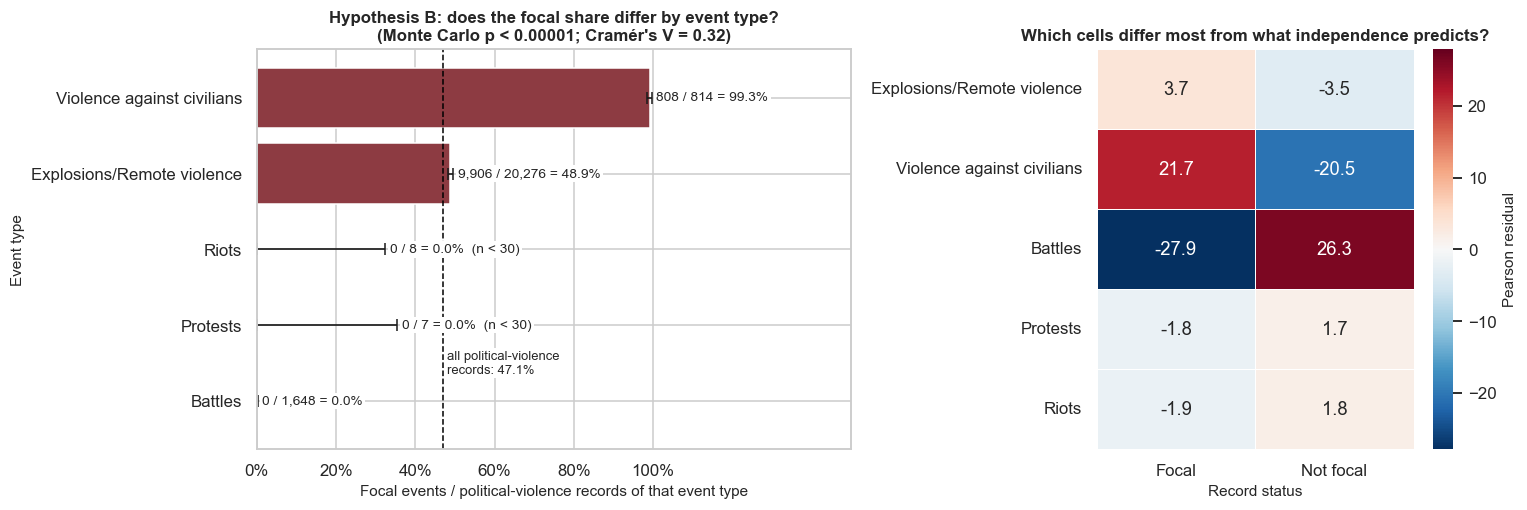

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

# Left: focal share within each event type, with 95% Wilson intervals; groups with fewer than 30 records are hatched
ax = axes[0]
tb = type_table.assign(n=type_table.sum(axis=1))
tb["share"] = tb.Focal / tb.n
tb = tb.sort_values("share")
small = (tb.n < 30).to_numpy()
cis_B = np.array([wilson_ci(k, n) for k, n in zip(tb.Focal, tb.n)])
bars = ax.barh(tb.index, tb.share, color=[C_GREY if s else C_FOCAL for s in small],
               xerr=[tb.share - cis_B[:, 0], cis_B[:, 1] - tb.share], capsize=4, error_kw={"lw": 1.1})
for b, s in zip(bars, small):
    if s:
        b.set_hatch("//")
for y, (_, r) in enumerate(tb.iterrows()):
    note = "  (n < 30)" if r.n < 30 else ""
    ax.text(cis_B[y, 1] + 0.012, y, f"{r.Focal:,.0f} / {r.n:,.0f} = {r.share:.1%}{note}", va="center", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
overall = tab_B[:, 0].sum() / n_B
ax.axvline(overall, color="black", ls="--", lw=1)
ax.text(overall + 0.008, 0.5, f"all political-violence\nrecords: {overall:.1%}", fontsize=8.5, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.grid(axis="x")
ax.set_xlim(0, 1.5); ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal events / political-violence records of that event type")
ax.set_ylabel("Event type")
ax.set_title(f"Hypothesis B: does the focal share differ by event type?\n(Monte Carlo {fmt_p(p_B, monte_carlo=True)}; Cramér's V = {V_B:.2f})")

# Right: which cells push the table away from independence
ax = axes[1]
lim = float(np.abs(resid_B.to_numpy()).max())
sns.heatmap(resid_B, annot=True, fmt=".1f", cmap="RdBu_r", vmin=-lim, vmax=lim, center=0,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "Pearson residual"}, ax=ax)
ax.grid(False)
ax.set_xlabel("Record status")
ax.set_ylabel("")
ax.set_title("Which cells differ most from what independence predicts?")
plt.tight_layout()
plt.show()

**Interpretation.** We reject H0 (chi-square(4) = 2,394.76, Monte Carlo p < 0.00001, Cramér's V = 0.32). None of the 99,999 simulated tables reached the observed statistic, so 0.00001 is the smallest p-value this run can report, not an exact value (BQ2). In plain terms, the focal share clearly depends on event type: Violence against civilians is almost entirely focal (808 of 814, 99.3%), Explosions/Remote violence is split (9,906 of 20,276, 48.9%) and Battles have none (0 of 1,648). The residuals put the largest departures from independence in Battles (focal cell -27.9), Violence against civilians (+21.7) and Explosions/Remote violence (+3.7), while Protests and Riots stay within about 2 of zero because 7 and 8 records cannot show a clear difference. The result does not depend on the sparse cells: with Protests and Riots pooled (15 records) every expected count is at least 5, the statistic is unchanged at 2,394.76 (both rare types have a focal share of 0) and the conclusion is the same, and Violence against civilians vs. Explosions/Remote violence alone gives chi-square(1) = 795.58 (p = 4.9e-175). The focal rule requires a civilian actor label, so part of this association is built into the coding: it describes how focal events are recorded across types, not which event types produce them.

### 4.5 Summary of Results

The table below collects the two tests. It reads the values computed above, so it updates if the data are re-exported.

In [36]:
summary = pd.DataFrame([
    {"Hypothesis": "A: focal share, before vs. after Oct 7, 2023", "BQ": "BQ1",
     "Test": "Pearson chi-square, 2 × 2", "Statistic": f"chi-square({dof_A}) = {chi2_A:,.2f}", "p-value": fmt_p(p_A),
     "Effect size": f"{diff * 100:+.1f} points; odds ratio {odds:.2f}; phi = {phi_A:.2f}", "Decision": decision_A},
    {"Hypothesis": "B: focal share across event types", "BQ": "BQ2",
     "Test": f"Chi-square, Monte Carlo p ({N_RESAMPLES:,} tables)", "Statistic": f"chi-square({dof_B}) = {chi2_B:,.2f}",
     "p-value": fmt_p(p_B, monte_carlo=True), "Effect size": f"Cramér's V = {V_B:.2f}", "Decision": decision_B},
]).set_index("Hypothesis")
print(f"Decision rule: reject H0 when p < {ALPHA / 2} (alpha = {ALPHA}, Bonferroni-adjusted for two primary tests)")
display(summary)

Decision rule: reject H0 when p < 0.025 (alpha = 0.05, Bonferroni-adjusted for two primary tests)


,BQ,Test,Statistic,p-value,Effect size,Decision
Hypothesis,,,,,,
"A: focal share, before vs. after Oct 7, 2023",BQ1,"Pearson chi-square, 2 × 2",chi-square(1) = 151.60,p = 7.76e-35,+31.4 points; odds ratio 4.71; phi = 0.08,Reject H0
B: focal share across event types,BQ2,"Chi-square, Monte Carlo p (99,999 tables)","chi-square(4) = 2,394.76",p < 0.00001,Cramér's V = 0.32,Reject H0


**Conclusions in plain language.**

- **Hypothesis A (BQ1): rejected H0.** If the focal share were the same before and after Oct 7, 2023, a gap as large as 16.2% vs. 47.6% would almost never occur by chance. From Oct 7 onward, a recorded political-violence event is about 2.9 times as likely to meet the focal rule, and the rise holds inside Explosions/Remote violence, so it is not only a change in the mix of event types.
- **Hypothesis B (BQ2): rejected H0.** The focal share depends strongly on event type: nearly all Violence against civilians records are focal, about half of Explosions/Remote violence records are, and none of the Battles records are. Protests and Riots are too rare to judge. Because the focal rule needs a civilian actor label, this pattern is partly a result of how the rule is built.

**What the tests do not show.**
- They do not show why the focal share changed. A change in events, in ACLED coding or in source coverage after Oct 7, 2023 would all produce the same table, and the earlier period holds only 389 political-violence records (63 focal).
- The p-values treat records as independent, but events cluster in time and place, so they are best read as strong exploratory evidence, not exact probabilities.
- Neither test shows intent, responsibility or a legal classification.

**For the insights writer and Phase 4 modelling.** (1) The rise in focal share is carried by Explosions/Remote violence (13.1% to 49.4%). (2) The event-type association is partly built into the focal rule and should be described that way. (3) The earlier period is sparse and its share is imprecise, which supports using it for description only and comparing weeks within the post-October 7 period in the models, as planned in Phase 2.

**References**

1. Group 7. *Phase 1: Dataset Selection and Business Problem* (business questions BQ1 to BQ5 and scope).
2. Group 7. *Phase 2: Data Preprocessing* (period definitions, focal-event rule, Monte Carlo chi-square test, `data/processed/` outputs).
3. Group 7. *Phase 3: Bivariate and Multivariate Analysis* (preflight diagnostics, Charts 1, 2, 7 and 11, handoff notes).
4. Mugot, C. J. S. *EDA Bivariate Analysis of Categorical Variables*, 2026.
5. SciPy documentation: `scipy.stats.chi2_contingency`, `MonteCarloMethod`, `fisher_exact`, `binomtest`.
6. ACLED. [Codebook](https://acleddata.com/methodology/acled-codebook). Definitions and interpretation limitations.
7. DS312. *Final Project Guide*, 1st Semester A.Y. 2026-2027 (Instructor: Nicole S. Menorias), hypothesis-testing requirement. Supplied course document.